# Triton on an A100: A Hands-On Guide

This notebook explains what Triton is and walks through its core features with runnable examples:

1. Vector addition and benchmarking with `triton.testing`
2. Fused softmax (row-wise reductions, kernel fusion)
3. Matrix multiplication with Tensor Cores, autotuning and a fused activation
4. Fusing elementwise operations (bias + GELU + residual) and comparing with `torch.compile`
5. Inspecting what the Triton compiler generates (IR and PTX)
6. Triton inside `torch.compile`

**Before you start:** in Colab go to *Runtime → Change runtime type* and select **A100 GPU**. The notebook also runs on other NVIDIA GPUs (T4, L4), but performance numbers will differ. Triton comes preinstalled with PyTorch in Colab.

## 0. Setup and GPU check

In [1]:
!nvidia-smi

Thu Nov 12 02:02:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   35C    P0             55W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
import torch
import triton
import triton.language as tl

assert torch.cuda.is_available(), "No GPU found. Change the runtime type to GPU (A100)."
DEVICE = torch.device("cuda")

props = torch.cuda.get_device_properties(0)
print(f"GPU:     {props.name}")
print(f"SMs:     {props.multi_processor_count}")
print(f"Triton:  {triton.__version__}")
print(f"PyTorch: {torch.__version__}")

if "A100" not in props.name:
    print("\nNote: this is not an A100. Everything will run, but timings will differ.")

GPU:     NVIDIA A100-SXM4-80GB
SMs:     108
Triton:  3.8.0
PyTorch: 2.14.1+cu130


## 1. What is Triton?

**Triton** is a language and compiler, created at OpenAI, for writing GPU kernels **in Python**. Its goal is to get performance close to expert-written CUDA with far less code and effort.

### The key difference: you program blocks, not threads

| | CUDA | Triton |
|---|---|---|
| Unit you program | One **thread** (a scalar) | One **program** that processes a **block** of data |
| Shared memory | You manage it | The compiler decides |
| Synchronization (`__syncthreads`) | You insert it | Automatic |
| Memory coalescing and vectorization | Manual | Automatic |
| Tensor Cores | Explicit WMMA/MMA | Automatic with `tl.dot` |
| Language | C++ | Python (a subset) |
| Hardware | NVIDIA only | NVIDIA, AMD and others |

### Core concepts

- `@triton.jit`: compiles the function as a GPU kernel (JIT, on first call).
- **Grid**: how many instances of the program to launch. `kernel[grid](args)`.
- `tl.program_id(axis)`: which instance am I (like `blockIdx` in CUDA).
- `tl.arange(0, BLOCK)`: a **vector** of indices; operations act on whole blocks.
- `tl.load` / `tl.store` with **masks**: to avoid reading or writing out of bounds (like `if (i < n)` in CUDA).
- `tl.constexpr`: compile-time parameters (block sizes). Block shapes must be powers of 2.
- Pointers are just PyTorch tensors: Triton kernels take `torch.Tensor` arguments directly.

### How it compiles

```
Python (@triton.jit) -> Triton IR -> Triton GPU IR (MLIR) -> LLVM IR -> PTX -> SASS (GPU binary)
```

On top of that, **PyTorch 2 (`torch.compile`) generates Triton kernels automatically**, so Triton is behind many models even if you never see it.

**Debugging tip:** setting the environment variable `TRITON_INTERPRET=1` before importing Triton runs kernels on the CPU with NumPy, so you can use `print` and the Python debugger inside them.

## 2. Example: vector addition

The simplest possible kernel. Note that:
- Each program instance processes `BLOCK_SIZE` elements at once (not one).
- The mask `offsets < n` plays the role of CUDA's `if (i < n)`.
- `grid` can be a function of the meta-parameters, so the grid size adapts to `BLOCK_SIZE`.

In [3]:
@triton.jit
def add_kernel(x_ptr, y_ptr, out_ptr, n_elements, BLOCK_SIZE: tl.constexpr):
    pid = tl.program_id(axis=0)                            # which block am I
    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)  # indices of my block
    mask = offsets < n_elements                            # stay in bounds
    x = tl.load(x_ptr + offsets, mask=mask)
    y = tl.load(y_ptr + offsets, mask=mask)
    tl.store(out_ptr + offsets, x + y, mask=mask)


def add(x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    out = torch.empty_like(x)
    n = out.numel()
    grid = lambda meta: (triton.cdiv(n, meta["BLOCK_SIZE"]),)
    add_kernel[grid](x, y, out, n, BLOCK_SIZE=1024)
    return out


x = torch.rand(98_432, device=DEVICE)
y = torch.rand(98_432, device=DEVICE)
print("Max difference vs PyTorch:", (add(x, y) - (x + y)).abs().max().item())

Max difference vs PyTorch: 0.0


### Benchmarking with `triton.testing`

Triton ships with benchmarking utilities:
- `triton.testing.do_bench(fn)`: returns time in milliseconds, with proper warm-up and synchronization.
- `@triton.testing.perf_report`: sweeps parameters and produces a table and a plot.

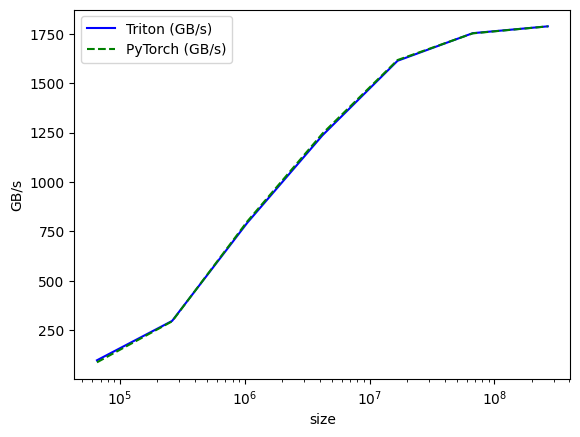

vector-add:
          size  Triton (GB/s)  PyTorch (GB/s)
0      65536.0      96.969697       86.676141
1     262144.0     296.173247      294.249366
2    1048576.0     792.817032      799.612590
3    4194304.0    1235.313501     1244.241158
4   16777216.0    1612.994275     1616.700312
5   67108864.0    1752.787010     1751.824460
6  268435456.0    1787.484840     1787.265794


In [4]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=["size"],
        x_vals=[2**i for i in range(16, 29, 2)],
        x_log=True,
        line_arg="provider",
        line_vals=["triton", "torch"],
        line_names=["Triton", "PyTorch"],
        styles=[("blue", "-"), ("green", "--")],
        ylabel="GB/s",
        plot_name="vector-add",
        args={},
    )
)
def bench_add(size, provider):
    x = torch.rand(size, device=DEVICE, dtype=torch.float32)
    y = torch.rand(size, device=DEVICE, dtype=torch.float32)
    fn = (lambda: add(x, y)) if provider == "triton" else (lambda: x + y)
    ms = triton.testing.do_bench(fn)
    return 3 * x.numel() * x.element_size() / (ms * 1e-3) / 1e9


bench_add.run(print_data=True, show_plots=True)

The two lines should be nearly identical: a memory-bound operation leaves little room for improvement, and Triton reaches the same bandwidth as PyTorch's native kernel in about 10 lines of Python.

## 3. Example: fused softmax

This is where Triton starts to win. A softmax written as separate PyTorch operations launches **several kernels**, and each one reads and writes the whole matrix from global memory:

```python
x_max = x.max(dim=1)          # reads x
z = x - x_max                 # reads x, writes z
num = torch.exp(z)            # reads z, writes num
den = num.sum(dim=1)          # reads num
out = num / den               # reads num, writes out
```

A **fused kernel** loads each row **once** into registers, does all the math there, and writes the result once. Less memory traffic means more speed.

In this kernel each program instance handles **one full row**. `tl.max` and `tl.sum` are reductions over the block.

In [5]:
@triton.jit
def softmax_kernel(out_ptr, in_ptr, in_row_stride, out_row_stride, n_cols, BLOCK_SIZE: tl.constexpr):
    row = tl.program_id(0)
    cols = tl.arange(0, BLOCK_SIZE)
    mask = cols < n_cols
    # Load the row; out-of-bounds positions are -inf so they don't affect the max
    x = tl.load(in_ptr + row * in_row_stride + cols, mask=mask, other=-float("inf"))
    x = x - tl.max(x, axis=0)          # numerical stability
    num = tl.exp(x)
    den = tl.sum(num, axis=0)
    tl.store(out_ptr + row * out_row_stride + cols, num / den, mask=mask)


def softmax(x: torch.Tensor) -> torch.Tensor:
    n_rows, n_cols = x.shape
    BLOCK_SIZE = triton.next_power_of_2(n_cols)    # block size must be a power of 2
    num_warps = 4 if BLOCK_SIZE < 2048 else (8 if BLOCK_SIZE < 4096 else 16)
    out = torch.empty_like(x)
    softmax_kernel[(n_rows,)](out, x, x.stride(0), out.stride(0), n_cols,
                              BLOCK_SIZE=BLOCK_SIZE, num_warps=num_warps)
    return out


def naive_softmax(x):
    x_max = x.max(dim=1, keepdim=True)[0]
    z = x - x_max
    num = torch.exp(z)
    den = num.sum(dim=1, keepdim=True)
    return num / den


x = torch.randn(1823, 781, device=DEVICE)
print("Matches torch.softmax?", torch.allclose(softmax(x), torch.softmax(x, dim=1), atol=1e-6))

Matches torch.softmax? True


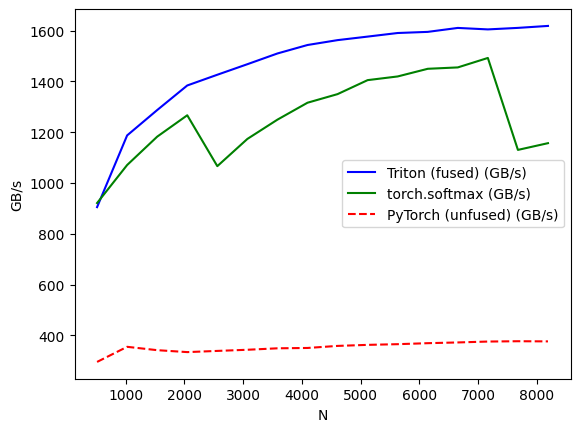

softmax:
         N  Triton (fused) (GB/s)  torch.softmax (GB/s)  PyTorch (unfused) (GB/s)
0    512.0             904.836294            920.905186                295.417026
1   1024.0            1187.216234           1070.632136                354.902942
2   1536.0            1287.034191           1182.297070                341.687891
3   2048.0            1383.808059           1266.491750                334.076486
4   2560.0            1426.039633           1066.158600                338.751124
5   3072.0            1467.545975           1173.337358                343.283811
6   3584.0            1509.803130           1249.260552                349.003747
7   4096.0            1543.116156           1315.899984                350.366213
8   4608.0            1562.331837           1349.774698                358.468213
9   5120.0            1576.220301           1404.836674                362.560520
10  5632.0            1590.370921           1419.334256                365.279107
11  614

In [6]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=["N"],
        x_vals=[256 * i for i in range(2, 33, 2)],
        line_arg="provider",
        line_vals=["triton", "torch", "naive"],
        line_names=["Triton (fused)", "torch.softmax", "PyTorch (unfused)"],
        styles=[("blue", "-"), ("green", "-"), ("red", "--")],
        ylabel="GB/s",
        plot_name="softmax",
        args={"M": 4096},
    )
)
def bench_softmax(M, N, provider):
    x = torch.randn(M, N, device=DEVICE, dtype=torch.float32)
    fns = {"triton": lambda: softmax(x),
           "torch": lambda: torch.softmax(x, dim=-1),
           "naive": lambda: naive_softmax(x)}
    ms = triton.testing.do_bench(fns[provider])
    return 2 * x.numel() * x.element_size() / (ms * 1e-3) / 1e9


bench_softmax.run(print_data=True, show_plots=True)

The unfused version should be well below the others since it makes several passes over memory. The Triton kernel should match `torch.softmax` (a hand-written CUDA kernel), or even beat it at some sizes.

## 4. Example: matrix multiplication with autotuning and Tensor Cores

This is the most important Triton example. It shows:

- **`tl.dot`**: multiplies two blocks and **uses Tensor Cores automatically**. Compare that with writing WMMA code by hand in CUDA.
- **2D pointer blocks**: `offs_m[:, None]` and `offs_k[None, :]` build a grid of addresses (NumPy-style broadcasting).
- **`@triton.autotune`**: tries several configurations (block sizes, number of warps, pipeline stages) and keeps the fastest for each matrix shape (`key`).
- **Grouped block ordering (`GROUP_M`)**: reorders which tile of C each program computes so that neighboring programs reuse the same A and B data in L2 cache.
- **Fusion**: applies an activation (Leaky ReLU) **before** writing the result, saving a kernel launch and a pass over memory.
- `num_stages`: how many memory loads are prefetched in the software pipeline (on the A100 this uses asynchronous copies).

In [7]:
def get_autotune_configs():
    return [
        triton.Config({"BLOCK_M": 128, "BLOCK_N": 256, "BLOCK_K": 64, "GROUP_M": 8}, num_stages=3, num_warps=8),
        triton.Config({"BLOCK_M": 64,  "BLOCK_N": 256, "BLOCK_K": 32, "GROUP_M": 8}, num_stages=4, num_warps=4),
        triton.Config({"BLOCK_M": 128, "BLOCK_N": 128, "BLOCK_K": 32, "GROUP_M": 8}, num_stages=4, num_warps=4),
        triton.Config({"BLOCK_M": 128, "BLOCK_N": 64,  "BLOCK_K": 32, "GROUP_M": 8}, num_stages=4, num_warps=4),
        triton.Config({"BLOCK_M": 64,  "BLOCK_N": 128, "BLOCK_K": 32, "GROUP_M": 8}, num_stages=4, num_warps=4),
        triton.Config({"BLOCK_M": 128, "BLOCK_N": 32,  "BLOCK_K": 32, "GROUP_M": 8}, num_stages=4, num_warps=4),
        triton.Config({"BLOCK_M": 64,  "BLOCK_N": 32,  "BLOCK_K": 32, "GROUP_M": 8}, num_stages=5, num_warps=2),
    ]


@triton.autotune(configs=get_autotune_configs(), key=["M", "N", "K"])
@triton.jit
def matmul_kernel(
    a_ptr, b_ptr, c_ptr,
    M, N, K,
    stride_am, stride_ak, stride_bk, stride_bn, stride_cm, stride_cn,
    BLOCK_M: tl.constexpr, BLOCK_N: tl.constexpr, BLOCK_K: tl.constexpr,
    GROUP_M: tl.constexpr, ACTIVATION: tl.constexpr,
):
    # --- 1. Which tile of C this program computes (grouped ordering for L2 reuse) ---
    pid = tl.program_id(axis=0)
    num_pid_m = tl.cdiv(M, BLOCK_M)
    num_pid_n = tl.cdiv(N, BLOCK_N)
    num_pid_in_group = GROUP_M * num_pid_n
    group_id = pid // num_pid_in_group
    first_pid_m = group_id * GROUP_M
    group_size_m = min(num_pid_m - first_pid_m, GROUP_M)
    pid_m = first_pid_m + ((pid % num_pid_in_group) % group_size_m)
    pid_n = (pid % num_pid_in_group) // group_size_m

    # --- 2. Pointers to the first blocks of A and B ---
    offs_am = (pid_m * BLOCK_M + tl.arange(0, BLOCK_M)) % M
    offs_bn = (pid_n * BLOCK_N + tl.arange(0, BLOCK_N)) % N
    offs_k = tl.arange(0, BLOCK_K)
    a_ptrs = a_ptr + offs_am[:, None] * stride_am + offs_k[None, :] * stride_ak
    b_ptrs = b_ptr + offs_k[:, None] * stride_bk + offs_bn[None, :] * stride_bn

    # --- 3. Loop over K, accumulating in FP32 ---
    acc = tl.zeros((BLOCK_M, BLOCK_N), dtype=tl.float32)
    for k in range(0, tl.cdiv(K, BLOCK_K)):
        a = tl.load(a_ptrs, mask=offs_k[None, :] < K - k * BLOCK_K, other=0.0)
        b = tl.load(b_ptrs, mask=offs_k[:, None] < K - k * BLOCK_K, other=0.0)
        acc += tl.dot(a, b)                 # Tensor Cores
        a_ptrs += BLOCK_K * stride_ak
        b_ptrs += BLOCK_K * stride_bk

    # --- 4. Fusion: activation applied in registers, before writing ---
    if ACTIVATION == "leaky_relu":
        acc = tl.where(acc >= 0, acc, 0.01 * acc)
    c = acc.to(tl.float16)

    # --- 5. Write the tile of C ---
    offs_cm = pid_m * BLOCK_M + tl.arange(0, BLOCK_M)
    offs_cn = pid_n * BLOCK_N + tl.arange(0, BLOCK_N)
    c_ptrs = c_ptr + offs_cm[:, None] * stride_cm + offs_cn[None, :] * stride_cn
    c_mask = (offs_cm[:, None] < M) & (offs_cn[None, :] < N)
    tl.store(c_ptrs, c, mask=c_mask)


def matmul(a: torch.Tensor, b: torch.Tensor, activation: str = "") -> torch.Tensor:
    assert a.shape[1] == b.shape[0], "Incompatible dimensions"
    M, K = a.shape
    K, N = b.shape
    c = torch.empty((M, N), device=a.device, dtype=torch.float16)
    grid = lambda meta: (triton.cdiv(M, meta["BLOCK_M"]) * triton.cdiv(N, meta["BLOCK_N"]),)
    matmul_kernel[grid](
        a, b, c, M, N, K,
        a.stride(0), a.stride(1), b.stride(0), b.stride(1), c.stride(0), c.stride(1),
        ACTIVATION=activation,
    )
    return c

In [8]:
torch.manual_seed(0)
a = torch.randn(512, 512, device=DEVICE, dtype=torch.float16)
b = torch.randn(512, 512, device=DEVICE, dtype=torch.float16)

print("Autotuning... the first call takes a few seconds.")
c_triton = matmul(a, b)
c_torch = a @ b
print("Matmul matches PyTorch?", torch.allclose(c_triton, c_torch, atol=1e-2, rtol=0))

c_triton = matmul(a, b, activation="leaky_relu")
c_torch = torch.nn.functional.leaky_relu(a @ b, 0.01)
print("Matmul + LeakyReLU matches?", torch.allclose(c_triton, c_torch, atol=1e-2, rtol=0))
print("\nBest config found for 512x512:", matmul_kernel.best_config)

Autotuning... the first call takes a few seconds.
Matmul matches PyTorch? True
Matmul + LeakyReLU matches? True

Best config found for 512x512: BLOCK_M: 64, BLOCK_N: 32, BLOCK_K: 32, GROUP_M: 8, num_warps: 2, num_ctas: 1, num_stages: 5, maxnreg: None


This takes 1-2 minutes because each size is autotuned.


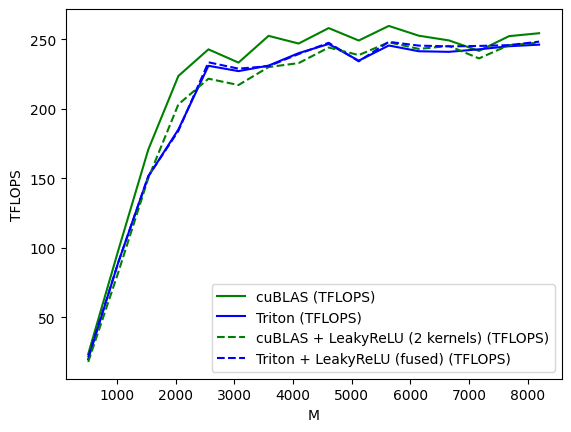

matmul-fp16:
         M       N       K  cuBLAS (TFLOPS)  Triton (TFLOPS)  cuBLAS + LeakyReLU (2 kernels) (TFLOPS)  Triton + LeakyReLU (fused) (TFLOPS)
0    512.0   512.0   512.0        23.658559        20.047406                                18.030190                            21.518307
1   1024.0  1024.0  1024.0        98.135028        89.609425                                82.404411                            89.482700
2   1536.0  1536.0  1536.0       170.770079       151.401702                               150.197589                           151.632419
3   2048.0  2048.0  2048.0       223.606638       185.176055                               203.207614                           184.143248
4   2560.0  2560.0  2560.0       242.745743       230.928314                               221.660055                           233.454303
5   3072.0  3072.0  3072.0       233.230177       227.104132                               217.098301                           228.866909
6   3584.0  35

In [9]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
        x_names=["M", "N", "K"],
        x_vals=[256 * i for i in range(2, 33, 2)],
        line_arg="provider",
        line_vals=["cublas", "triton", "cublas+act", "triton+act"],
        line_names=["cuBLAS", "Triton", "cuBLAS + LeakyReLU (2 kernels)", "Triton + LeakyReLU (fused)"],
        styles=[("green", "-"), ("blue", "-"), ("green", "--"), ("blue", "--")],
        ylabel="TFLOPS",
        plot_name="matmul-fp16",
        args={},
    )
)
def bench_matmul(M, N, K, provider):
    a = torch.randn((M, K), device=DEVICE, dtype=torch.float16)
    b = torch.randn((K, N), device=DEVICE, dtype=torch.float16)
    fns = {
        "cublas": lambda: a @ b,
        "triton": lambda: matmul(a, b),
        "cublas+act": lambda: torch.nn.functional.leaky_relu(a @ b, 0.01),
        "triton+act": lambda: matmul(a, b, activation="leaky_relu"),
    }
    ms = triton.testing.do_bench(fns[provider])
    return 2 * M * N * K * 1e-12 / (ms * 1e-3)


print("This takes 1-2 minutes because each size is autotuned.")
bench_matmul.run(print_data=True, show_plots=True)

With ~70 lines of Python, Triton should land close to cuBLAS (thousands of lines of hand-tuned code), and the fused version with the activation should beat cuBLAS + a separate activation at several sizes.

## 5. Example: fusing elementwise ops (bias + GELU + residual)

In a transformer it's very common to compute `y = residual + GELU(x + bias)`. In eager PyTorch that's **3 kernels** (add, GELU, add), each with its own pass over memory. In Triton it's **one**.

This example also shows:
- **Broadcasting** via indexing: the bias has shape `(N,)` and is applied to every row using `offsets % N`.
- Triton math functions (`tl.sigmoid`).
- The approximation `GELU(x) ≈ x · sigmoid(1.5958 · (x + 0.044715 x³))`, which is exactly the `tanh` form of GELU rewritten.
- Mixed precision: load FP16, compute in FP32, store back in the output's dtype.

We also compare against **`torch.compile`**, which automatically generates a fused Triton kernel.

In [10]:
@triton.jit
def bias_gelu_residual_kernel(x_ptr, bias_ptr, res_ptr, out_ptr, n_elements, N, BLOCK_SIZE: tl.constexpr):
    pid = tl.program_id(0)
    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)
    mask = offsets < n_elements
    x = tl.load(x_ptr + offsets, mask=mask).to(tl.float32)
    bias = tl.load(bias_ptr + offsets % N, mask=mask).to(tl.float32)   # row-wise broadcasting
    res = tl.load(res_ptr + offsets, mask=mask).to(tl.float32)

    h = x + bias
    gelu = h * tl.sigmoid(1.5957691216057308 * (h + 0.044715 * h * h * h))  # GELU (tanh)
    out = res + gelu
    tl.store(out_ptr + offsets, out.to(out_ptr.dtype.element_ty), mask=mask)


def bias_gelu_residual(x, bias, residual):
    out = torch.empty_like(x)
    n = x.numel()
    grid = lambda meta: (triton.cdiv(n, meta["BLOCK_SIZE"]),)
    bias_gelu_residual_kernel[grid](x, bias, residual, out, n, x.shape[-1], BLOCK_SIZE=1024)
    return out


def torch_eager(x, bias, residual):
    return residual + torch.nn.functional.gelu(x + bias, approximate="tanh")


torch_compiled = torch.compile(torch_eager)

M, N = 8192, 8192
x = torch.randn(M, N, device=DEVICE, dtype=torch.float16)
bias = torch.randn(N, device=DEVICE, dtype=torch.float16)
res = torch.randn(M, N, device=DEVICE, dtype=torch.float16)

ref = torch_eager(x, bias, res)
print("Triton matches PyTorch?", torch.allclose(bias_gelu_residual(x, bias, res), ref, atol=1e-2, rtol=1e-2))
torch_compiled(x, bias, res)  # compiles (takes a few seconds the first time)

bytes_moved = 3 * x.numel() * x.element_size()   # reads x and residual, writes out (bias is negligible)
for name, fn in [("PyTorch eager (3 kernels)", torch_eager),
                 ("torch.compile (auto Triton)", torch_compiled),
                 ("Hand-written Triton (1 kernel)", bias_gelu_residual)]:
    ms = triton.testing.do_bench(lambda: fn(x, bias, res))
    print(f"{name:32s} {ms:6.3f} ms   {bytes_moved / (ms * 1e-3) / 1e9:6.0f} effective GB/s")

Triton matches PyTorch? True
PyTorch eager (3 kernels)         0.733 ms      550 effective GB/s
torch.compile (auto Triton)       0.241 ms     1671 effective GB/s
Hand-written Triton (1 kernel)    0.239 ms     1682 effective GB/s


## 6. Example: looking inside what Triton generates

Launching a Triton kernel returns an object that holds the intermediate code from every compiler stage:

- `ttir`: Triton IR (high level)
- `ttgir`: Triton GPU IR (with decisions about how data is distributed across threads)
- `llir`: LLVM IR
- `ptx`: NVIDIA's virtual assembly, the same thing `nvcc` would produce

This is useful for understanding what the compiler did, for example looking for `mma` instructions in the matmul to confirm it uses Tensor Cores.

In [11]:
x = torch.rand(4096, device=DEVICE)
y = torch.rand(4096, device=DEVICE)
out = torch.empty_like(x)
compiled = add_kernel[(4,)](x, y, out, x.numel(), BLOCK_SIZE=1024)

print("Available stages:", list(compiled.asm.keys()))
print("\n===== Triton IR (beginning) =====")
print("\n".join(compiled.asm["ttir"].splitlines()[:25]))
print("\n===== PTX (global loads/stores, note the vectorized .v4 accesses) =====")
ptx_lines = compiled.asm["ptx"].splitlines()
print("\n".join([l for l in ptx_lines if "ld.global" in l or "st.global" in l][:10]))

Available stages: ['source', 'ttir', 'ttgir', 'llir', 'ptx', 'cubin']

===== Triton IR (beginning) =====
#loc = loc("/tmp/ipykernel_674/2917242380.py":2:1)
#loc13 = loc("x_ptr"(#loc))
#loc14 = loc("y_ptr"(#loc))
#loc15 = loc("out_ptr"(#loc))
#loc16 = loc("n_elements"(#loc))
module {
  tt.func public @add_kernel(%x_ptr: !tt.ptr<f32> {tt.divisibility = 16 : i32} loc("x_ptr"(#loc)), %y_ptr: !tt.ptr<f32> {tt.divisibility = 16 : i32} loc("y_ptr"(#loc)), %out_ptr: !tt.ptr<f32> {tt.divisibility = 16 : i32} loc("out_ptr"(#loc)), %n_elements: i32 {tt.divisibility = 16 : i32} loc("n_elements"(#loc))) attributes {noinline = false} {
    %c1024_i32 = arith.constant 1024 : i32 loc(#loc1)
    %pid = tt.get_program_id x : i32 loc(#loc17)
    %offsets = arith.muli %pid, %c1024_i32 : i32 loc(#loc18)
    %offsets_0 = tt.make_range {end = 1024 : i32, start = 0 : i32} : tensor<1024xi32> loc(#loc19)
    %offsets_1 = tt.splat %offsets : i32 -> tensor<1024xi32> loc(#loc18)
    %offsets_2 = arith.addi %offset

In [12]:
# Does the matmul use Tensor Cores? Look for mma instructions in the PTX
a = torch.randn(1024, 1024, device=DEVICE, dtype=torch.float16)
b = torch.randn(1024, 1024, device=DEVICE, dtype=torch.float16)
matmul(a, b)  # make sure autotuning has picked a config for this shape
cfg = matmul_kernel.best_config
print("Config used:", cfg)

M, K = a.shape; N = b.shape[1]
c = torch.empty((M, N), device=DEVICE, dtype=torch.float16)
grid = (triton.cdiv(M, cfg.kwargs["BLOCK_M"]) * triton.cdiv(N, cfg.kwargs["BLOCK_N"]),)
compiled_mm = matmul_kernel.fn[grid](
    a, b, c, M, N, K, a.stride(0), a.stride(1), b.stride(0), b.stride(1), c.stride(0), c.stride(1),
    ACTIVATION="", num_warps=cfg.num_warps, num_stages=cfg.num_stages, **cfg.kwargs,
)
mma = [l.strip() for l in compiled_mm.asm["ptx"].splitlines() if "mma" in l]
print(f"mma (Tensor Core) instructions in the PTX: {len(mma)}")
print("Example:", mma[0] if mma else "none")

Config used: BLOCK_M: 128, BLOCK_N: 128, BLOCK_K: 32, GROUP_M: 8, num_warps: 4, num_ctas: 1, num_stages: 4, maxnreg: None
mma (Tensor Core) instructions in the PTX: 64
Example: mma.sync.aligned.m16n8k16.row.col.f32.f16.f16.f32 { %r501, %r502, %r503, %r504 }, { %r174, %r175, %r176, %r177 }, { %r178, %r179 }, { %r501, %r502, %r503, %r504 };


## 7. Example: Triton inside `torch.compile`

`torch.compile` (PyTorch 2's compiler backend, called *Inductor*) analyzes your PyTorch code, fuses operations and **writes Triton kernels automatically**. You can look at the code it generates.

That means every PyTorch user is already using Triton, even without writing a line of it.

In [13]:
from torch._inductor.utils import run_and_get_code


def layer(x, w):
    return torch.nn.functional.silu(x) * w + 1.0


x = torch.randn(4096, 4096, device=DEVICE)
w = torch.randn(4096, device=DEVICE)
compiled_layer = torch.compile(layer)
_, codes = run_and_get_code(compiled_layer, x, w)

code = codes[0]
start = code.find("@triton.jit")
print(code[start:start + 2500] if start >= 0 else code[:2500])

@triton.jit
def triton_poi_fused_add_mul_silu_0(in_ptr0, in_ptr1, out_ptr0, xnumel, XBLOCK : tl.constexpr):
    xnumel = 16777216
    xoffset = tl.program_id(0) * XBLOCK
    xindex = xoffset + tl.arange(0, XBLOCK)[:]
    xmask = tl.full([XBLOCK], True, tl.int1)[:]
    x2 = xindex
    x0 = (xindex % 4096)
    tmp0 = tl.load(in_ptr0 + (x2), None)
    tmp6 = tl.load(in_ptr1 + (x0), None, eviction_policy='evict_last')
    tmp1 = -tmp0
    tmp2 = libdevice.exp(tmp1)
    tmp3 = tl.full([1], 1.0, tl.float32)
    tmp4 = tmp2 + tmp3
    tmp5 = (tmp0 / tmp4)
    tmp7 = tmp5 * tmp6
    tmp8 = tmp7 + tmp3
    tl.store(out_ptr0 + (x2), tmp8, None)
''', device_str='cuda')


async_compile.wait(globals())
del async_compile

class Runner:
    def __init__(self, partitions):
        self.partitions = partitions

    def recursively_apply_fns(self, fns):
        new_callables = []
        for fn, c in zip(fns, self.partitions):
            new_callables.append(fn(c))
        self.partitions = new_callabl

---
## Summary: when to use what

| Situation | Recommendation |
|---|---|
| Standard ops (matmul, convolutions, attention) | Use PyTorch / cuBLAS / cuDNN / FlashAttention: already optimized |
| You want to speed up a model without writing kernels | `torch.compile` (it writes Triton for you) |
| You need a new op or want to fuse several | **Triton**: quick to write, good performance, portable to AMD |
| You need the last 10–20% of performance, fine control over warps, memory or hardware-specific instructions | **CUDA** (or CUTLASS / CuTe) |

### Further reading

- The official Triton tutorials at triton-lang.org (several examples here are based on them).
- Source code of fused Triton kernels in projects like FlashAttention, Unsloth and Liger Kernel, to see production-grade kernels.
- PyTorch's `torch.compile` documentation, to understand what Inductor generates.